In [1]:
# Preparar un entorno reproducible y ubicar los archivos sin pedir rutas interactivas.
from pathlib import Path
import json, sys, importlib.metadata, itertools, hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
SEED = 42
rng = np.random.default_rng(SEED)
ARCHIVOS = {'costos':'Viajes con Costos V2.csv',
            'tiempos':'Tiempos Viajes Foraneos.csv',
            'ciclos':'Detalle Ciclos de Viajes Despachados.csv'}
bases = [Path.cwd()/'data', Path.cwd(), Path.cwd()/'upload', Path.cwd()/'datos', Path.cwd().parent/'upload', Path.cwd().parents[1]/'upload']
DATA = next((p for p in bases if all((p/n).is_file() for n in ARCHIVOS.values())), None)
if DATA is None:
    raise FileNotFoundError('Coloca los tres CSV originales en data/, junto al notebook o en una carpeta upload/ o datos/.')
OUT = Path.cwd()/'resultados_ternium'
OUT.mkdir(exist_ok=True)
plt.rcParams.update({'font.family':'DejaVu Sans','font.size':10,'axes.spines.top':False,
                     'axes.spines.right':False,'figure.dpi':130,'savefig.dpi':200})
def mostrar(df): print(df.to_string(index=False))
def figura(fig, nombre):
    fig.tight_layout(); fig.savefig(OUT/nombre,bbox_inches='tight'); plt.show(); plt.close(fig)
def tabla(df,nombre):
    df.to_csv(OUT/nombre,index=False,encoding='utf-8-sig'); mostrar(df)
def ptexto(p): return '< 1e-300' if p == 0 else f'{p:.3g}'
print('Python:',sys.version.split()[0])
versiones={n:importlib.metadata.version(n) for n in ['pandas','numpy','scipy','scikit-learn','matplotlib']}
print('Versiones:',versiones)
# Los CSV usan ';' y BOM. El de costos trae punto de miles, coma decimal y fechas d/mm/aa;
# su Monto total llega redondeado a pesos enteros.
LECTURA={'costos':dict(thousands='.',decimal=',')}
datos={k:pd.read_csv(DATA/n,sep=';',encoding='utf-8-sig',low_memory=False,**LECTURA.get(k,{})) for k,n in ARCHIVOS.items()}
c,t,d=datos['costos'],datos['tiempos'],datos['ciclos']
c['Peso Total']=c['Peso Total'].astype('int64');c['Monto total']=c['Monto total'].astype(float)
for col in ['F.Salida','F.CargaP']: c[col]=pd.to_datetime(c[col],format='%d/%m/%y')
resumen={'versiones':versiones,'semilla':SEED,
         'archivos_sha256':{n:hashlib.sha256((DATA/n).read_bytes()).hexdigest() for n in ARCHIVOS.values()}}

Python: 3.12.0
Versiones: {'pandas': '2.3.3', 'numpy': '2.5.1', 'scipy': '1.18.1', 'scikit-learn': '1.9.0', 'matplotlib': '3.11.1'}


## Auditoría del contrafactual
Pregunta: ¿se registra el costo y la disponibilidad de cada camión elegible que no se usó?

La evidencia se obtiene del inventario completo de columnas y de la estructura de los registros. `Monto total` está ligado al `Viaje` realizado; no existe una lista de alternativas para ese mismo viaje con tarifas y disponibilidad a la hora de decidir. `FAMILIA_CAMION_DESC` y `Desc TpoTrn` describen equipos observados, no todos los candidatos.

**Conclusión de alcance:** el contrafactual no está registrado explícitamente en los tres archivos recibidos. Esto no demuestra que Ternium carezca de esos registros en otros sistemas. No se recibió el listado formal de datos solicitados; no podemos auditar pedido versus recepción ni afirmar que Ternium rechazó proporcionarlos.

In [2]:
# Documentar TODAS las columnas; evitar deducir ausencias a partir de unas pocas muestras.
inventario=pd.DataFrame([{'Archivo':ARCHIVOS[k],'Columna':col,'Tipo':str(df[col].dtype),
                        'Faltantes':int(df[col].isna().sum()),'Valores distintos':int(df[col].nunique())}
                       for k,df in datos.items() for col in df.columns])
tabla(inventario,'inventario_columnas.csv')
auditoria=pd.DataFrame([
 ['Camión usado','Sí','Desc TpoTrn / FAMILIA_CAMION_DESC'],
 ['Costo observado','Sí','Monto total; Moneda = MXN'],
 ['Peso transportado','Sí, unidad pendiente','Peso Total'],
 ['Tarifa del camión no usado','No explícita','Sin tabla de alternativas por decisión'],
 ['Disponibilidad al asignar','No explícita','Sin estado de flota a la hora de decisión'],
 ['Capacidad por equipo y peso por eje','No explícita','Los nombres de ejes no dan límites de carga'],
 ['Volumen, dimensiones y producto','No explícitos','Sin medidas o catálogo de productos'],
 ['Ventana de entrega acordada','No explícita','ETA y ETA_FLEX requieren diccionario'],
 ['Pedido dividido o consolidado','No reconstruible','Hay #Remitos, pero no IDs de pedido por remito']
],columns=['Dato necesario','Resultado','Evidencia'])
tabla(auditoria,'auditoria_contrafactual.csv')
print('Monedas observadas:',c.Moneda.value_counts().to_dict())
print('Estados de tiempos:',t.ESTADO.value_counts().to_dict())
print('Categorías de ciclos:',d['Cant. Ciclos'].value_counts().to_dict())
resumen['auditoria']=auditoria.to_dict('records')

                                 Archivo                  Columna           Tipo  Faltantes  Valores distintos
                Viajes con Costos V2.csv                    Viaje          int64          0              91619
                Viajes con Costos V2.csv                  Permiso          int64          0              90542
                Viajes con Costos V2.csv            Planta Origen         object          0                 49
                Viajes con Costos V2.csv            Desc Org. Apt         object          0                 50
                Viajes con Costos V2.csv                   Nombre         object          0                164
                Viajes con Costos V2.csv               TpoTrn.APT          int64          0                 23
                Viajes con Costos V2.csv              Desc TpoTrn         object          0                  8
                Viajes con Costos V2.csv                   TpoSrv         object       5369                  2
 

## Fenómeno 1 · La unidad de observación
Pregunta guía: ¿una fila representa un viaje completo o un registro asociado a él?

Se cuentan filas, IDs distintos, IDs repetidos y duplicados exactos en **cada archivo**. Una repetición de ID no es por sí misma un error: puede representar destinos, actualizaciones, documentos o eventos. Se inspeccionan diferencias de columnas sin mostrar datos personales.

Para las estadísticas adoptamos una unidad operativa conservadora: un viaje con un solo registro de costos y una sola combinación inequívoca de origen, destino, camión y fechas en tiempos. Colapsamos únicamente proyecciones idénticas de tiempos; excluimos los IDs con combinaciones distintas. No agregamos costos repetidos ni asignamos a mano un destino. Esta selección reduce cobertura y sus resultados no representan automáticamente toda la flota.

Archivo  Filas  IDs únicos  IDs con varias filas  Filas adicionales por ID  Duplicados exactos
 costos  91772       91619                   145                       153                   0
tiempos 105449       93239                 10296                     12210                   7
 ciclos   7476        6051                  1232                      1425                   0
Archivo             Columna  IDs repetidos con diferencias
 costos             Permiso                            140
 costos       Planta Origen                            134
 costos       Desc Org. Apt                            134
 costos          TpoTrn.APT                              1
 costos              TpoSrv                              5
 costos            F.Salida                             57
 costos            H.Salida                            140
 costos            #Remitos                             36
 costos          Peso Total                              5
 costos            Shp.Cost   

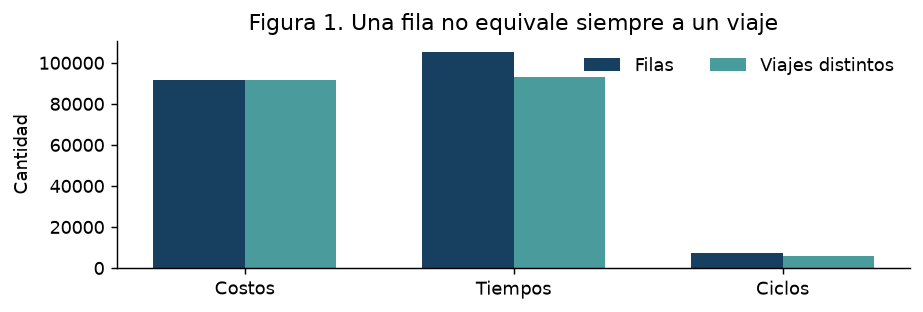

                                  Paso  Cantidad
               Filas costos originales     91772
         Viajes costos sin ID repetido     91474
   Viajes tiempos con proyección única     82954
               Viajes unidos uno a uno     76071
                  Origen inconsistente         1
Base final positiva y origen coherente     76070
     Etapa  Faltantes  Negativos  Mediana no negativa
  Espera_h       5844          2             0.433333
  Planta_h       5844         27             3.266667
Traslado_h      21083          2            26.964722


In [3]:
# Medir repetición y verificar qué campos cambian dentro del mismo identificador.
ids={'costos':'Viaje','tiempos':'ID_VIAJE_NCA','ciclos':'ID Viaje'}
for k,df in datos.items():
    df[ids[k]]=df[ids[k]].astype('string').str.replace(r'\.0$','',regex=True).str.strip()
filas=[]; conflictos=[]
for k,df in datos.items():
    conteos=df[ids[k]].value_counts()
    filas.append({'Archivo':k,'Filas':len(df),'IDs únicos':df[ids[k]].nunique(),
                  'IDs con varias filas':int((conteos>1).sum()),
                  'Filas adicionales por ID':len(df)-df[ids[k]].nunique(),
                  'Duplicados exactos':int(df.duplicated().sum())})
    multi=df[df[ids[k]].duplicated(False)]
    for col in df.columns:
        if col not in [ids[k],'Chofer','Placas tract','Placas plat']:
            n=int((multi.groupby(ids[k])[col].nunique(dropna=False)>1).sum())
            if n: conflictos.append({'Archivo':k,'Columna':col,'IDs repetidos con diferencias':n})
unidades=pd.DataFrame(filas);tabla(unidades,'unidad_observacion.csv')
tabla(pd.DataFrame(conflictos),'diferencias_por_id.csv')
fig,ax=plt.subplots(figsize=(7.2,2.5))
x=np.arange(3); ax.bar(x-.17,unidades.Filas,width=.34,label='Filas',color='#173F5F')
ax.bar(x+.17,unidades['IDs únicos'],width=.34,label='Viajes distintos',color='#4A9B9C')
ax.set_xticks(x,['Costos','Tiempos','Ciclos']);ax.set_ylabel('Cantidad');ax.set_title('Figura 1. Una fila no equivale siempre a un viaje')
ax.legend(frameon=False,ncol=2);ax.ticklabel_format(axis='y',style='plain')
figura(fig,'figura_1_unidades.png')
cc=c.loc[~c.Viaje.duplicated(False)].copy()
campos_t=['ID_VIAJE_NCA','COD_PLANTA_ORIGEN','D_REGION','ZONA_LOCALIDAD','GEOCERCA_ID',
          'TIPO_DESPACHO','FAMILIA_CAMION_DESC','FECHA_PRESENTACION','FECHA_INGRESO','FECHA_EGRESO',
          'FECHA_LLEGADA_GEO_CERCA']
tt=t[campos_t].drop_duplicates().copy()
tt=tt.loc[~tt.ID_VIAJE_NCA.duplicated(False)].copy()
b=cc.merge(tt,left_on='Viaje',right_on='ID_VIAJE_NCA',how='inner',validate='one_to_one')
origen_ok=b['Planta Origen'].astype('string').eq(b.COD_PLANTA_ORIGEN.astype('string'))
flujo={'Filas costos originales':len(c),'Viajes costos sin ID repetido':len(cc),
       'Viajes tiempos con proyección única':len(tt),'Viajes unidos uno a uno':len(b),
       'Origen inconsistente':int((~origen_ok).sum())}
b=b.loc[origen_ok].copy()
for col in ['Peso Total','Monto total','#Remitos']:
    b[col]=pd.to_numeric(b[col],errors='coerce')
validos=(b['Peso Total']>0)&(b['Monto total']>0)&(b['#Remitos']>0)
b=b.loc[validos].copy()
b['Ruta']=b['Planta Origen'].astype('string')+' → '+b.D_REGION.astype('string')+' / '+b.ZONA_LOCALIDAD.astype('string')
b['Fecha']=pd.to_datetime(b['F.Salida'],errors='coerce')
for col in ['FECHA_PRESENTACION','FECHA_INGRESO','FECHA_EGRESO','FECHA_LLEGADA_GEO_CERCA']:
    b[col]=pd.to_datetime(b[col],format='%d/%m/%Y %H:%M:%S',errors='coerce')
pares={'Espera_h':('FECHA_PRESENTACION','FECHA_INGRESO'),
       'Planta_h':('FECHA_INGRESO','FECHA_EGRESO'),
       'Traslado_h':('FECHA_EGRESO','FECHA_LLEGADA_GEO_CERCA')}
calidad=[]
for nombre,(ini,fin) in pares.items():
    h=(b[fin]-b[ini]).dt.total_seconds()/3600
    calidad.append({'Etapa':nombre,'Faltantes':int(h.isna().sum()),'Negativos':int((h<0).sum()),
                    'Mediana no negativa':float(h[h>=0].median())})
    b[nombre]=h.mask(h<0) # Una duración negativa es no interpretable; no se reemplaza por cero.
flujo['Base final positiva y origen coherente']=len(b)
tabla(pd.DataFrame(list(flujo.items()),columns=['Paso','Cantidad']),'flujo_muestra.csv')
tabla(pd.DataFrame(calidad),'calidad_tiempos.csv')
resumen.update({'unidades':unidades.to_dict('records'),'flujo':flujo,'calidad_tiempos':calidad,
 'coincidencias_costos_tiempos':len(set(c.Viaje)&set(t.ID_VIAJE_NCA)),
 'coincidencias_tres':len(set(c.Viaje)&set(t.ID_VIAJE_NCA)&set(d['ID Viaje']))})
assert b.Viaje.is_unique

**Lectura de figura 1:** tiempos tiene 105,449 filas para 93,239 IDs; ciclos 7,476 para 6,051; costos 91,772 para 91,619. Cambios de destino/geocerca y planta muestran que no son meros duplicados. La selección produce 76,070 viajes con unión uno a uno; es conservadora y pierde cobertura.

## Análisis 1 · Distribuciones y anomalías
Pregunta: ¿los valores extremos y la falta de fechas alteran la historia que contaríamos con un promedio?

Se describen peso y costo en toda la tabla de costos, sin borrar extremos. Se reportan mediana, percentiles, media, desviación estándar, asimetría y proporción fuera de la regla de Tukey (1.5 veces el rango intercuartílico). Esa regla marca observaciones para revisión: no certifica errores. El umbral de peso >100,000 se usa únicamente como señal de auditoría, no como límite legal. La unidad del peso sigue pendiente; no presentamos toneladas ni utilización.

Las figuras usan eje logarítmico para hacer visibles tanto la concentración como la cola, y conservan los valores originales. La log-transformación para PCA no convierte los datos en normales ni corrige errores de captura.

   Variable     n        Media  Mediana  Desv estándar      P95      P99     Máximo  Asimetría  Fuera de Tukey %
 Peso Total 91772 30363.834732  29381.5  278179.565111 36612.45 43115.35 62058000.0 171.746718          5.174781
Monto total 91772 27404.848865  21738.0   20914.327957 70182.00 97191.00   185000.0   1.627048          3.495620


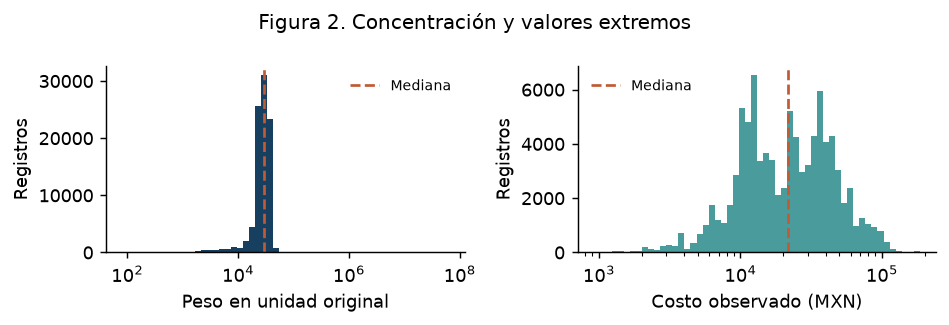

   Viaje Desc TpoTrn  Peso Total  Monto total
73838769      2_EJES      302000      22000.0
73882999      2_EJES      322000      22000.0
73884302      2_EJES     3176000      22000.0
73900374      2_EJES    62058000      22000.0
73910245      2_EJES     1309000      22000.0
73950296      2_EJES      302000      22000.0
73945478      2_EJES      334000      22000.0
73944058      2_EJES      322000      22000.0
73954841      2_EJES      709000      11000.0
73845828      2_EJES     1306000      36635.0
73949260      2_EJES    13700000       7817.0
73955369      2_EJES      754000      11000.0
73992588      2_EJES      303000      22000.0
73992873      2_EJES      575000      22000.0
73852932      2_EJES    13885000      22000.0
74101573      2_EJES      328000      11000.0
74160647   CAMIONETA      120000       3090.0
74199117   CAMIONETA      134000       1545.0
74273636      2_EJES      235000      36635.0
74298398      2_EJES     9243000      36635.0
74293224      2_EJES     2515000  

In [4]:
# Comparar centro y cola antes de proponer transformaciones.
distrib=[]
for col in ['Peso Total','Monto total']:
    s=pd.to_numeric(c[col],errors='coerce').dropna()
    q1,q3=s.quantile([.25,.75]);iqr=q3-q1
    distrib.append({'Variable':col,'n':len(s),'Media':s.mean(),'Mediana':s.median(),
     'Desv estándar':s.std(),'P95':s.quantile(.95),'P99':s.quantile(.99),'Máximo':s.max(),
     'Asimetría':stats.skew(s,bias=False),'Fuera de Tukey %':100*((s<q1-1.5*iqr)|(s>q3+1.5*iqr)).mean()})
distrib=pd.DataFrame(distrib);tabla(distrib,'distribuciones.csv')
fig,axs=plt.subplots(1,2,figsize=(7.4,2.5))
for ax,col,color in zip(axs,['Peso Total','Monto total'],['#173F5F','#4A9B9C']):
    s=pd.to_numeric(c[col],errors='coerce');s=s[s>0]
    ax.hist(s,bins=np.geomspace(s.min(),s.max(),55),color=color)
    ax.set_xscale('log');ax.axvline(s.median(),color='#C05B36',ls='--',label='Mediana')
    ax.set_xlabel('Peso en unidad original' if col=='Peso Total' else 'Costo observado (MXN)')
    ax.set_ylabel('Registros');ax.legend(frameon=False,fontsize=8)
fig.suptitle('Figura 2. Concentración y valores extremos',fontsize=11)
figura(fig,'figura_2_distribuciones.png')
extremos=c.loc[pd.to_numeric(c['Peso Total'],errors='coerce')>100000,['Viaje','Desc TpoTrn','Peso Total','Monto total']]
tabla(extremos,'pesos_para_validar.csv')
resumen['distribuciones']=distrib.to_dict('records');resumen['pesos_mayores_100000']=len(extremos)
resumen['faltante_llegada_original']=int(t.FECHA_LLEGADA_GEO_CERCA.isna().sum())

**Lectura de figura 2:** peso mediano 29,381.5 y máximo 62,058,000; 44 valores superan 100,000 y requieren confirmación de unidad y captura. Costo mediano MXN 21,738 frente a media 27,404.85: la cola derecha eleva la media. Escala logarítmica expone concentración y extremos, sin certificar errores.

## Fenómeno 2 · El sesgo de lo que se observa
Pregunta guía: ¿la mezcla de tipos de camión es similar entre plantas, o la asignación histórica ya filtra lo que podemos comparar?

Analizamos plantas y tipos con al menos 500 viajes en la base conservadora; documentamos la cobertura y verificamos frecuencias esperadas antes de interpretar chi-cuadrada. Cramér V acompaña al p-value para medir magnitud. El p-value de chi-cuadrada presupone independencia de observaciones, que viajes repetidos de un mismo proveedor/ruta pueden incumplir; se interpreta como evidencia exploratoria bajo ese supuesto. Una dependencia no demuestra una mala asignación ni identifica su causa. El mapa resume porcentajes dentro de cada planta y no expresa utilización.

Planta Origen  2_EJES  3_EJES  CAMIONETA  MENORES  PORTACINTAS
         BSLO       0     649          0        0           41
         BSR2     177     396          0        0            0
          CHU     943    6834          0        0          649
         CSCA    4840     157          1        0            3
         CSIA      69    1909          0        0          147
         CSIS     378     520          0        0           59
          GDL      40       0        397      612            0
          GUE    1549    6651          0        0          231
          JUV    2275    5140          0        0          190
          LAP    3508    4402          0        0            5
          LEO      10      67        203      325            0
          LPU     757    7981          0        0            0
          MEX    1097      50         35      216            0
          MVA       0    1112          0        0            3
          PSQ    2463   11922          0        0      

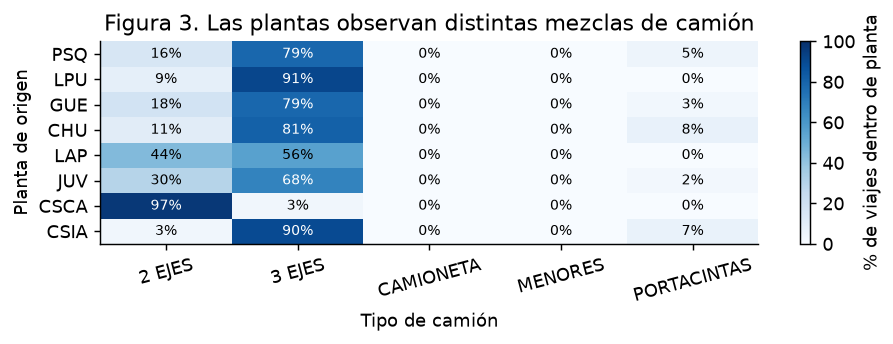

In [5]:
# Medir la estructura de selección histórica y no confundir presencia con elegibilidad.
plantas=b['Planta Origen'].value_counts();tipos=b['Desc TpoTrn'].value_counts()
sesgo=b[b['Planta Origen'].isin(plantas[plantas>=500].index)&b['Desc TpoTrn'].isin(tipos[tipos>=500].index)]
ct=pd.crosstab(sesgo['Planta Origen'],sesgo['Desc TpoTrn'])
chi,pchi,dof,esperados=stats.chi2_contingency(ct,correction=False)
v=np.sqrt(chi/(ct.to_numpy().sum()*min(ct.shape[0]-1,ct.shape[1]-1)))
por=ct.div(ct.sum(axis=1),axis=0)*100
tabla(ct.reset_index(),'planta_tipo_conteos.csv')
tabla(por.reset_index(),'planta_tipo_porcentajes.csv')
print('Chi2:',chi,'gl:',dof,'p:',ptexto(pchi),'Cramér V:',v,'mínimo esperado:',esperados.min())
resumen['sesgo']={'n':len(sesgo),'cobertura_base':len(sesgo)/len(b),'chi2':chi,'gl':dof,
 'p':float(pchi),'cramer_v':v,'min_esperado':float(esperados.min()),'plantas':len(ct),'tipos':len(ct.columns)}
top=b['Planta Origen'].value_counts().head(8).index
vista=por.loc[[i for i in top if i in por.index]]
fig,ax=plt.subplots(figsize=(7.3,2.75))
im=ax.imshow(vista,cmap='Blues',vmin=0,vmax=100,aspect='auto')
ax.set_xticks(range(len(vista.columns)),[str(i).replace('_',' ') for i in vista.columns],rotation=15)
ax.set_yticks(range(len(vista)),vista.index);ax.set_xlabel('Tipo de camión');ax.set_ylabel('Planta de origen')
for i in range(len(vista)):
    for j in range(len(vista.columns)):
        valor=vista.iloc[i,j];ax.text(j,i,f'{valor:.0f}%',ha='center',va='center',fontsize=8,color='white' if valor>60 else 'black')
fig.colorbar(im,ax=ax,label='% de viajes dentro de planta')
ax.set_title('Figura 3. Las plantas observan distintas mezclas de camión')
figura(fig,'figura_3_sesgo.png')

**Lectura de figura 3:** la mezcla de camiones cambia por planta. Chi2=82,775.21, gl=64, p<1e-300, V=0.535 y mínimo esperado=6.67 en 72,219 viajes. La asociación describe la selección observada, no la disponibilidad del camión descartado ni la causa de la asignación. La figura muestra ocho plantas; la prueba usa 17.

## Análisis 2 · Relaciones y validación estadística
Pregunta: ¿las asociaciones con el costo persisten al comparar viajes dentro de una misma ruta?

Usamos Spearman por la asimetría y los extremos. Tres relaciones predefinidas: peso–costo, remitos–costo y traslado–costo. Además de rho y n se reportan p-values bilaterales y corrección Holm de esas tres pruebas. Los p-values asintóticos presuponen independencia; se agrega una sensibilidad por ruta con una mediana por ruta (al menos 30 viajes). La independencia entre rutas también es una aproximación.

Para peso–costo calculamos una asociación dentro de ruta, restando a los rangos su media por ruta. Un contraste por permutación mezcla los costos SOLO dentro de cada ruta, con semilla fija y 999 repeticiones, en rutas con al menos 30 viajes. Es un contraste exploratorio que presupone intercambiabilidad dentro de ruta y no controla producto, contrato, fecha o proveedor. Ninguna prueba estima el costo del camión alternativo. El costo por tonelada no se calcula sin confirmar la unidad del peso.

          Relación     n       rho             p        p Holm
Peso Total / costo 76070  0.013981  1.151891e-04  1.151891e-04
  #Remitos / costo 76070 -0.084563 9.806596e-121 1.961319e-120
Traslado_h / costo 54985  0.670671  0.000000e+00  0.000000e+00


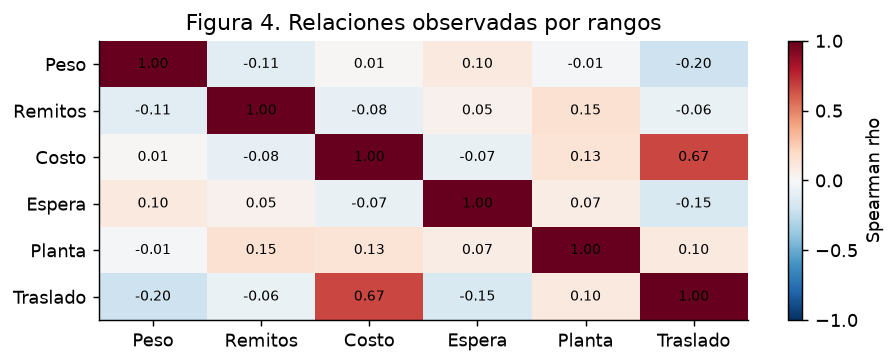

Control exploratorio dentro de ruta: {'n': 64594, 'rutas': 403, 'r_rangos_centrados': 0.20812493621220451, 'p_permutacion': 0.001, 'permutaciones': 999, 'rho_medianas_ruta': 0.007798124456282903, 'p_medianas_ruta': 0.8759838599299515}
Nota: p=0 en el cálculo asintótico significa subdesbordamiento numérico, no probabilidad nula.


In [6]:
# Reportar tamaño del efecto y distinguir asociación global de mezcla de rutas.
def holm(ps):
    ps=np.array(ps,dtype=float);orden=np.argsort(ps);aj=np.empty(len(ps))
    aj[orden]=np.minimum(1,np.maximum.accumulate(ps[orden]*(len(ps)-np.arange(len(ps)))))
    return aj
pruebas=[]
for col in ['Peso Total','#Remitos','Traslado_h']:
    z=b[[col,'Monto total']].dropna()
    rho,p=stats.spearmanr(z[col],z['Monto total'])
    pruebas.append({'Relación':col+' / costo','n':len(z),'rho':rho,'p':p})
pruebas=pd.DataFrame(pruebas);pruebas['p Holm']=holm(pruebas.p)
tabla(pruebas,'correlaciones.csv')
num=['Peso Total','#Remitos','Monto total','Espera_h','Planta_h','Traslado_h']
corr=b[num].corr(method='spearman')
fig,ax=plt.subplots(figsize=(7.2,2.9))
im=ax.imshow(corr,cmap='RdBu_r',vmin=-1,vmax=1,aspect='auto')
labels=['Peso','Remitos','Costo','Espera','Planta','Traslado']
ax.set_xticks(range(6),labels);ax.set_yticks(range(6),labels)
for i in range(6):
    for j in range(6):ax.text(j,i,f'{corr.iloc[i,j]:.2f}',ha='center',va='center',fontsize=8)
ax.set_title('Figura 4. Relaciones observadas por rangos')
fig.colorbar(im,ax=ax,label='Spearman rho')
figura(fig,'figura_4_correlaciones.png')
frecuencias=b.Ruta.value_counts()
z=b[b.Ruta.isin(frecuencias[frecuencias>=30].index)].copy()
rx=z['Peso Total'].rank().to_numpy();ry=z['Monto total'].rank().to_numpy()
grupos=[a for a in z.groupby('Ruta',sort=True).indices.values()]
for idx in grupos:
    rx[idx]-=rx[idx].mean();ry[idx]-=ry[idx].mean()
den=np.linalg.norm(rx)*np.linalg.norm(ry)
r_dentro=float(np.dot(rx,ry)/den)
conteo=0
# La prueba conserva la ruta; no compara una ruta larga con otra corta.
for _ in range(999):
    yp=ry.copy()
    for idx in grupos:yp[idx]=rng.permutation(ry[idx])
    conteo+=abs(float(np.dot(rx,yp)/den))>=abs(r_dentro)
p_perm=(conteo+1)/1000
med=z.groupby('Ruta')[['Peso Total','Monto total']].median()
rho_med,p_med=stats.spearmanr(med['Peso Total'],med['Monto total'])
resumen['relaciones']=pruebas.to_dict('records')
resumen['dentro_ruta']={'n':len(z),'rutas':len(grupos),'r_rangos_centrados':r_dentro,
                      'p_permutacion':p_perm,'permutaciones':999,
                      'rho_medianas_ruta':float(rho_med),'p_medianas_ruta':float(p_med)}
print('Control exploratorio dentro de ruta:',resumen['dentro_ruta'])
print('Nota: p=0 en el cálculo asintótico significa subdesbordamiento numérico, no probabilidad nula.')

**Lectura de figura 4 y pruebas:** peso–costo rho=0.014, remitos–costo rho=-0.085 y traslado–costo rho=0.671. Los dos primeros efectos son pequeños aunque significativos. Dentro de 403 rutas (origen, región y localidad), la asociación de rangos peso–costo es 0.208 y p de permutación=0.001. Entre medianas de rutas rho=0.008, p=0.876. Las mezclas de rutas pueden ocultar estructura; las asociaciones no prueban ahorros ni causalidad.

## Fenómenos 3 y 4 · Línea base y dimensión que limita
Pregunta guía de fenómeno 3: ¿podemos medir utilización real por tipo de camión, ruta y producto?

**Respuesta:** podemos describir peso, costo y mezcla de camiones por rutas observadas. No podemos calcular utilización real sin capacidad aplicable, producto y restricciones, ni atribuir espacio libre a desperdicio. La mediana de peso histórico no se usa como capacidad máxima.

Pregunta guía de fenómeno 4: ¿qué restricciones y acuerdos no se pueden distinguir?

Faltan volumen, dimensiones, peso por eje, configuración detallada, capacidad aplicable por equipo, producto y ventanas acordadas. Los nombres 2_EJES/3_EJES no son una ficha de capacidad. La hipótesis de consolidación con horarios flexibles no puede contrastarse directamente con ETA_FLEX sin conocer su definición y sin pedido/remito individual. Estas ausencias cambian el diseño: la primera línea base será descriptiva y las recomendaciones exigirán un catálogo de restricciones y alternativas elegibles.

In [7]:
# Fotografiar el patrón actual sin etiquetar cargas como subutilizadas.
base=b.groupby(['Planta Origen','D_REGION','ZONA_LOCALIDAD','Desc TpoTrn'],dropna=False).agg(
    viajes=('Viaje','size'),peso_mediano=('Peso Total','median'),
    costo_mediano_MXN=('Monto total','median'),remitos_medianos=('#Remitos','median'))
base=base.sort_values('viajes',ascending=False).reset_index()
tabla(base.head(12),'linea_base_top12.csv')
base.to_csv(OUT/'linea_base_completa.csv',index=False,encoding='utf-8-sig')
resumen['linea_base_top12']=base.head(12).to_dict('records')

Planta Origen        D_REGION  ZONA_LOCALIDAD Desc TpoTrn  viajes  peso_mediano  costo_mediano_MXN  remitos_medianos
          PSQ        COAHUILA        CASTAÑOS      3_EJES    2558       26975.0            12050.0               1.0
          PSQ        COAHUILA    RAMOS ARIZPE      3_EJES    1961       31744.0             9900.0               1.0
         CSCA          MEXICO       TULTITLAN      2_EJES    1517       24872.0            38400.0               1.0
          PSQ SAN LUIS POTOSI SAN LUIS POTOSI      3_EJES    1147       31700.0            25927.0               1.0
          GUE        COAHUILA CIUDAD FRONTERA      3_EJES    1118       36125.0            11400.0               1.0
          PSQ      TAMAULIPAS        ALTAMIRA      2_EJES     980       22985.0            14359.0               1.0
          CHU        COAHUILA    RAMOS ARIZPE      3_EJES     975       29748.0             9900.0               1.0
          GUE        COAHUILA    RAMOS ARIZPE      3_EJES     94

## Análisis 3 · PCA con y sin variables de resultado
Pregunta: ¿peso, remitos y tiempos forman una estructura común, y cambia al incorporar el costo?

PCA descriptivo sobre los mismos casos completos. Sin resultado: peso, remitos, espera en ingreso, permanencia en planta y traslado. Con resultado: se añade monto total. Los tiempos son medidas históricas; si un modelo se usa antes del despacho, esos tiempos realizados aún no están disponibles y no deben usarse como predictores de ese momento. Se aplican log1p y estandarización para reducir asimetría y evitar que unidades de mayor escala dominen. No se imputan fechas ni se incluyen IDs, placas o códigos numéricos de categoría. La sensibilidad limita valores al P1–P99 tras log1p; el análisis principal NO elimina ni limita extremos.

Comparamos varianza explicada y coeficientes de los primeros componentes. Los signos pueden invertirse sin cambiar el PCA y las varianzas de los dos modelos corresponden a espacios diferentes; no es una comparación de rendimiento predictivo ni una prueba causal.

   Modelo  Componente  Varianza  Acumulada
Sin costo           1  0.241613   0.241613
Sin costo           2  0.229671   0.471284
Sin costo           3  0.201753   0.673037
Sin costo           4  0.176822   0.849859
Sin costo           5  0.150141   1.000000
Con costo           1  0.285896   0.285896
Con costo           2  0.201179   0.487074
Con costo           3  0.178226   0.665301
Con costo           4  0.149211   0.814511
Con costo           5  0.132784   0.947296
Con costo           6  0.052704   1.000000
   Modelo    Variable       CP1       CP2
Sin costo  Peso Total  0.022342 -0.484646
Sin costo    #Remitos  0.636101  0.065992
Sin costo    Espera_h  0.464441 -0.424000
Sin costo    Planta_h  0.615153  0.300806
Sin costo  Traslado_h -0.027511  0.700359
Con costo  Peso Total  0.028499  0.056999
Con costo    #Remitos -0.010017  0.633505
Con costo    Espera_h -0.084075  0.504382
Con costo    Planta_h  0.251220  0.569791
Con costo  Traslado_h  0.676779 -0.127067
Con costo Monto total 

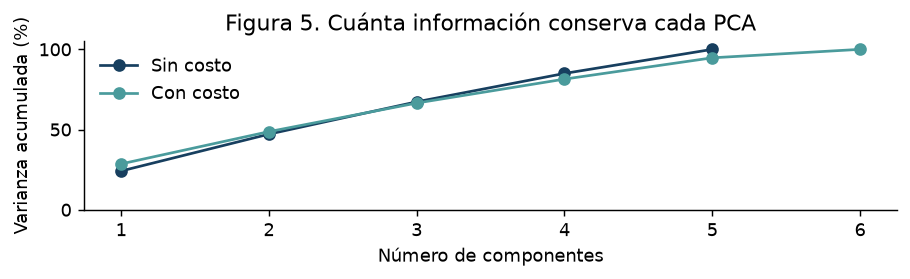

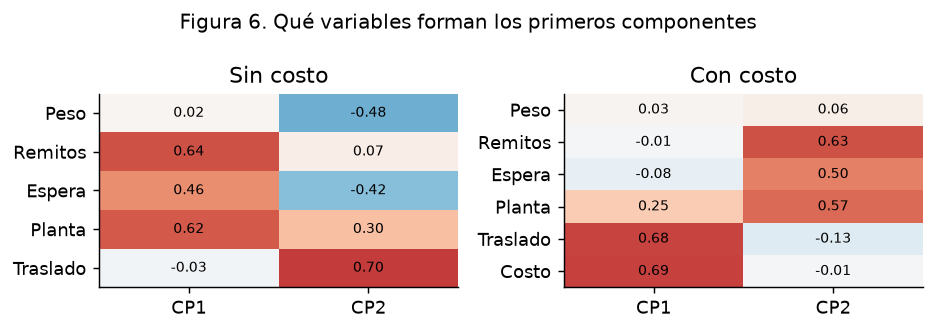

 Completo     n  peso_mediano  costo_mediano
    False 24142       29101.5        20776.0
     True 51928       29414.5        22800.0


In [8]:
# Usar la misma muestra en ambos PCA para que la diferencia sea de variables, no de filas.
entradas=['Peso Total','#Remitos','Espera_h','Planta_h','Traslado_h']
completo=b[entradas+['Monto total']].dropna().copy()
modelos={};ev=[];cargas=[]
for etiqueta,cols in [('Sin costo',entradas),('Con costo',entradas+['Monto total'])]:
    X=np.log1p(completo[cols])
    escalador=StandardScaler();A=escalador.fit_transform(X)
    modelo=PCA(svd_solver='full',random_state=SEED).fit(A)
    modelos[etiqueta]=modelo
    for j,val in enumerate(modelo.explained_variance_ratio_):
        ev.append({'Modelo':etiqueta,'Componente':j+1,'Varianza':val,
                   'Acumulada':modelo.explained_variance_ratio_[:j+1].sum()})
    # Orientar el signo solo para facilitar lectura de figuras.
    comp=modelo.components_.copy()
    for j in range(len(comp)):
        if comp[j,np.argmax(abs(comp[j]))]<0:comp[j]*=-1
    for i,col in enumerate(cols):
        cargas.append({'Modelo':etiqueta,'Variable':col,'CP1':comp[0,i],'CP2':comp[1,i]})
    clipped=X.clip(lower=X.quantile(.01),upper=X.quantile(.99),axis=1)
    sens=PCA(svd_solver='full').fit(StandardScaler().fit_transform(clipped))
    resumen.setdefault('pca',{})[etiqueta]={'n':len(completo),'variables':cols,
     'varianza':modelo.explained_variance_ratio_.tolist(),
     'acumulada_2':float(modelo.explained_variance_ratio_[:2].sum()),
     'acumulada_2_sensibilidad':float(sens.explained_variance_ratio_[:2].sum())}
ev=pd.DataFrame(ev);cargas=pd.DataFrame(cargas)
tabla(ev,'pca_varianza.csv');tabla(cargas,'pca_coeficientes.csv')
fig,ax=plt.subplots(figsize=(7.1,2.25))
for etiqueta,color in [('Sin costo','#173F5F'),('Con costo','#4A9B9C')]:
    v=ev[ev.Modelo==etiqueta];ax.plot(v.Componente,v.Acumulada*100,'o-',label=etiqueta,color=color)
ax.set_xlabel('Número de componentes');ax.set_ylabel('Varianza acumulada (%)')
ax.set_xticks(range(1,7));ax.set_ylim(0,105);ax.legend(frameon=False)
ax.set_title('Figura 5. Cuánta información conserva cada PCA')
figura(fig,'figura_5_pca_varianza.png')
fig,axs=plt.subplots(1,2,figsize=(7.3,2.55))
labels={'Peso Total':'Peso','#Remitos':'Remitos','Espera_h':'Espera','Planta_h':'Planta',
        'Traslado_h':'Traslado','Monto total':'Costo'}
for ax,etiqueta in zip(axs,['Sin costo','Con costo']):
    z=cargas[cargas.Modelo==etiqueta].set_index('Variable')[['CP1','CP2']]
    im=ax.imshow(z,cmap='RdBu_r',vmin=-1,vmax=1,aspect='auto')
    ax.set_xticks([0,1],['CP1','CP2']);ax.set_yticks(range(len(z)),[labels[i] for i in z.index])
    ax.set_title(etiqueta)
    for i in range(len(z)):
        for j in range(2):ax.text(j,i,f'{z.iloc[i,j]:.2f}',ha='center',va='center',fontsize=8)
fig.suptitle('Figura 6. Qué variables forman los primeros componentes',fontsize=11)
figura(fig,'figura_6_pca_coeficientes.png')
resumen['pca_coeficientes']=cargas.to_dict('records')
resumen['pca_cobertura_base']=len(completo)/len(b)
seleccion=b.assign(Completo=b[entradas+['Monto total']].notna().all(axis=1)).groupby('Completo').agg(
    n=('Viaje','size'),peso_mediano=('Peso Total','median'),costo_mediano=('Monto total','median'))
tabla(seleccion.reset_index(),'sesgo_casos_completos.csv')

**Lectura de figuras 5 y 6:** dos componentes explican 47.1% sin costo y 48.7% con costo; cuatro superan 80%. Sin costo, CP1 combina remitos y operación en planta. Al incluir costo, CP1 combina traslado y costo. Sensibilidad P1–P99: 47.8% y 48.8%. La conclusión no depende mucho de las colas, pero sí debe considerarse selección: costo mediano 22,800 en casos completos frente a 20,776 en los demás. Los tiempos realizados son posteriores a la decisión de despacho.

## Qué cambia para el diseño del proyecto
- El contrafactual no está explícito: no se cuantifican ahorros de reasignación con este histórico.
- La fila no equivale siempre a viaje o pedido: la unión requiere verificar granularidad y se documenta el flujo de exclusiones.
- La asociación planta–camión describe selección histórica, no conveniencia causal ni disponibilidad alternativa.
- La línea base de utilización por producto no es calculable con los campos disponibles. Se conserva una base descriptiva de viajes para comparar cobertura y comportamiento.
- El PCA es una exploración de estructura, no un modelo de asignación. Incluir costo y tiempos futuros en un modelo usado antes del despacho produciría fuga de información.

**Datos por solicitar o confirmar:** diccionario y unidad del peso; vínculo pedido–remito–viaje–parada; alternativas elegibles y tarifas vigentes al decidir; inventario disponible con marca de tiempo; capacidades y restricciones por equipo/producto/ruta; ventanas de entrega acordadas y definición de ETA_FLEX; contratos, distancia y reglas de consolidación. No se afirma que estos datos se solicitaron previamente.

**Fuentes:** los tres CSV originales de `data/` y la consigna del Componente 2. Documentación metodológica primaria: [Spearman en SciPy](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.spearmanr.html), [permutaciones en SciPy](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.permutation_test.html), [chi-cuadrada en SciPy](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.chi2_contingency.html), [PCA](https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.PCA.html) y [StandardScaler](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html).

In [9]:
# Guardar evidencia agregada y verificaciones; no exportar nombres o placas.
(OUT/'resumen.json').write_text(json.dumps(resumen,ensure_ascii=False,indent=2,default=str),encoding='utf-8')
assert b.Viaje.is_unique, 'La base de análisis debe contener un registro por viaje.'
assert len(completo)>500, 'Revisar cobertura de casos completos antes de interpretar PCA.'
assert all((OUT/f'figura_{n}_{s}.png').exists() for n,s in [
 (1,'unidades'),(2,'distribuciones'),(3,'sesgo'),(4,'correlaciones'),(5,'pca_varianza'),(6,'pca_coeficientes')])
print('Validaciones realizadas: IDs únicos, muestra PCA suficiente y seis figuras generadas.')
print('Resultados guardados en:',OUT)

Validaciones realizadas: IDs únicos, muestra PCA suficiente y seis figuras generadas.
Resultados guardados en: C:\Users\hecto\AppData\Local\Temp\nbwork\run_csv\resultados_ternium
